# Problem Statement : House Prices Prediction using TensorFlow Decision Forests

Ask a home buyer to describe their dream house, and they probably won't begin with the height of the basement ceiling or the proximity to an east-west railroad. But this playground competition's dataset proves that much more influences price negotiations than the number of bedrooms or a white-picket fence.

### Step to Follow

1. Requierd Library
2. Load dataset
3. Understand the data

In [1]:
import os
print(os.listdir('/kaggle/working'))

['__notebook__.ipynb']


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


# 1) Requierd Library

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
!pip install ydf

In [4]:
!pip install ydf

In [5]:
url = '/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv'
df = pd.read_csv(url)

Understand dataset size

In [6]:
shape_of_the_data = df.shape

print('Shpe of the data :',shape_of_the_data)
print('view the top reocrd',df.head())

Shpe of the data : (1460, 81)
view the top reocrd    Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType

# Find the missing values
let's understand the missing value why becauss the missing value can make big differnt so we to be carful.

Formula is  sum_of_all_value / Numbser_of_values *100 or 

[X1+X2+X+X4+X5...XN/ N *100](http://)

In [7]:
def handling_missing_value(data):
    missing = data.isnull().sum()
    missing_per = (missing / len(data)*100).round(2)
    result = pd.DataFrame({'Missing_Count' : missing , 'missing_%' : missing_per })
    return result[result['Missing_Count']>0].sort_values('missing_%',ascending= False)
handling_missing_value(df)

,Missing_Count,missing_%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


# 3) Understand the data
Check the data type of each if we know that would be better to make the decession 
so we have 
  * object   43
  * int      35
  * float    3

In [8]:
print(df.dtypes.value_counts())
print(len(df.select_dtypes(include='object').columns.tolist()))

object     43
int64      35
float64     3
Name: count, dtype: int64
43


## list the number columns

we have total of 38 numarical columns 

In [9]:
num_cols = df.select_dtypes(exclude='object').columns.tolist()
print(len(num_cols))
print(num_cols)

38
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


# Count the unique values in suspicious columns

In [10]:
print(df['MSSubClass'].nunique(), df['MoSold'].nunique())

15 12


# Prove it with the data (don’t just trust my claim)

In [11]:
print((df['PoolArea']== 0 ).sum())
print((df['Fireplaces']== 0 ).sum())
print((df['GarageArea']== 0 ).sum())
print((df['TotalBsmtSF']== 0 ).sum())
print((df['GarageCond']== 0 ).sum())



1453
690
81
37
0


In [12]:
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
df[none_cols] = df[none_cols].fillna('None')

df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['GarageYrBlt'].mean())
handling_missing_value(df)

,Missing_Count,missing_%


**All the value's has been fixed now **

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Mean: 180921.19589041095
Median: 163000.0
Skew: 1.8828757597682129


<Axes: >

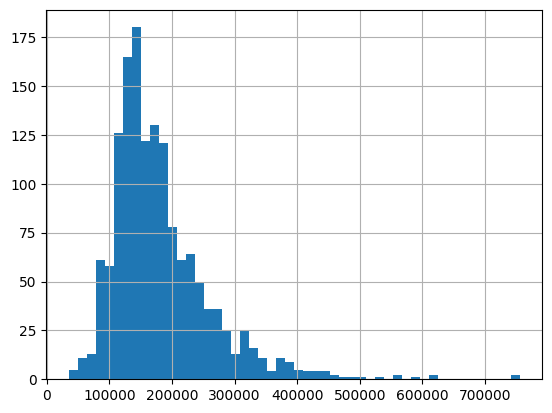

In [13]:
print(df['SalePrice'].describe())
print("Mean:", df['SalePrice'].mean())
print("Median:", df['SalePrice'].median())
print("Skew:", df['SalePrice'].skew())
df['SalePrice'].hist(bins=50)

1. Based on the record we can see that total rows *[1460](http://)*

2. Avg price of the each home *[180921.195890](http://)*

3. what we can understand that from the visual is  most of the house in the range between of *[1.5L](http://)* to *[2L](http://)*.

4. very less we can see the max amount of the price *[7.5L](http://)* also we can see very less min of the home price less then 80k 

In [14]:
print(df[['Neighborhood', 'SalePrice']].groupby('Neighborhood').mean().sort_values('SalePrice', ascending=False))

                  SalePrice
Neighborhood               
NoRidge       335295.317073
NridgHt       316270.623377
StoneBr       310499.000000
Timber        242247.447368
Veenker       238772.727273
Somerst       225379.837209
ClearCr       212565.428571
Crawfor       210624.725490
CollgCr       197965.773333
Blmngtn       194870.882353
Gilbert       192854.506329
NWAmes        189050.068493
SawyerW       186555.796610
Mitchel       156270.122449
NAmes         145847.080000
NPkVill       142694.444444
SWISU         142591.360000
Blueste       137500.000000
Sawyer        136793.135135
OldTown       128225.300885
Edwards       128219.700000
BrkSide       124834.051724
BrDale        104493.750000
IDOTRR        100123.783784
MeadowV        98576.470588


# as we can se the salse by Neighborhood or place 
1. the moset expencive place is '[NoRidge       335295.317073](http://)'
2. most least place is MeadowV        98576.470588

In [15]:
stats = df.groupby('Neighborhood')['SalePrice'].agg(['count', 'mean', 'median']).sort_values('mean')
print(stats)

              count           mean    median
Neighborhood                                
MeadowV          17   98576.470588   88000.0
IDOTRR           37  100123.783784  103000.0
BrDale           16  104493.750000  106000.0
BrkSide          58  124834.051724  124300.0
Edwards         100  128219.700000  121750.0
OldTown         113  128225.300885  119000.0
Sawyer           74  136793.135135  135000.0
Blueste           2  137500.000000  137500.0
SWISU            25  142591.360000  139500.0
NPkVill           9  142694.444444  146000.0
NAmes           225  145847.080000  140000.0
Mitchel          49  156270.122449  153500.0
SawyerW          59  186555.796610  179900.0
NWAmes           73  189050.068493  182900.0
Gilbert          79  192854.506329  181000.0
Blmngtn          17  194870.882353  191000.0
CollgCr         150  197965.773333  197200.0
Crawfor          51  210624.725490  200624.0
ClearCr          28  212565.428571  200250.0
Somerst          86  225379.837209  225500.0
Veenker   

## Find which number columns move with SalePrice

In [16]:
corr = df.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
print(corr.head(10))
print(corr.tail(5))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64


# Understanding of the correlation.
1) see the price based on what feture  is increasing the price.

2) Based on [overall quality](http://) the price is increasing we can understand much more that lets see in the ploting.

3) when the [living area](http://) is increasing the price is also increasing.

4) the whole understanding is when the area is growing or if it new house or new feture is added in the home there will be chance to go higher price. 

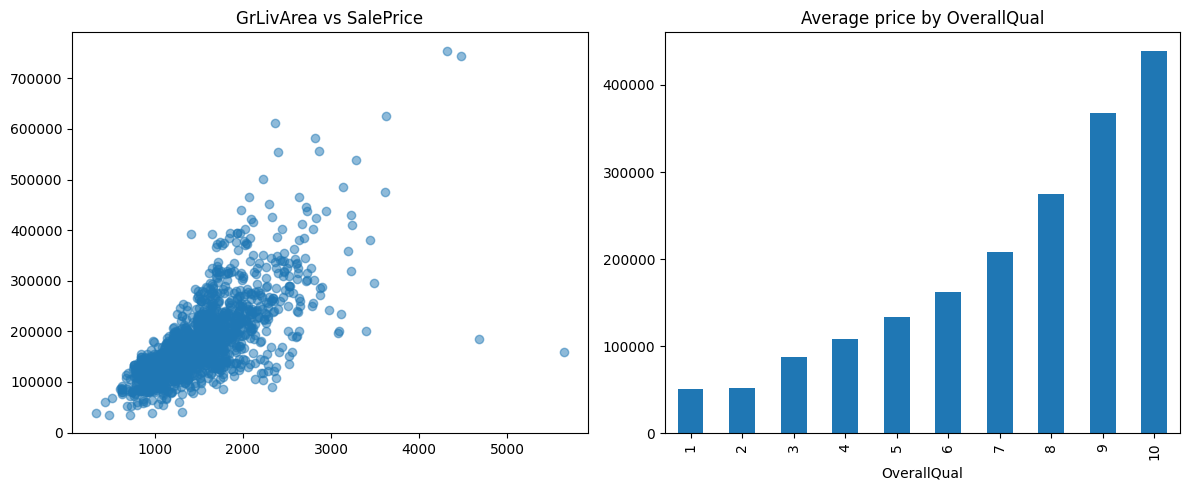

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(df['GrLivArea'], df['SalePrice'], alpha=0.5)
axes[0].set_title('GrLivArea vs SalePrice')
df.groupby('OverallQual')['SalePrice'].mean().plot(kind='bar', ax=axes[1], title='Average price by OverallQual')
plt.tight_layout()
plt.show()

we can see in the plot how price's are increasing when i have minmal sqf area my cost is less but when i have big living area my price is increasing also in the over all quality too when my 

# What do the prices look like, and does the log fix their shape?

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Mean: 180921 | Median: 163000
Skew raw: 1.88
Skew after log: 0.12


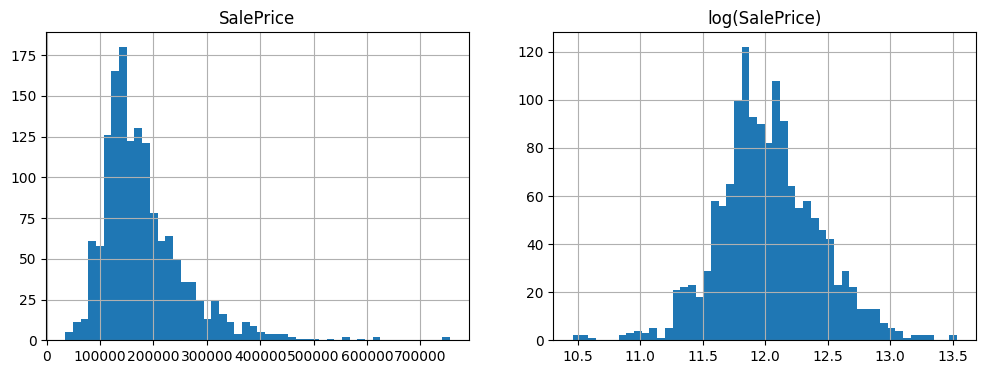

In [18]:
price = df['SalePrice']
print(price.describe())
print("Mean:", round(price.mean()), "| Median:", round(price.median()))
print("Skew raw:", round(price.skew(), 2))
print("Skew after log:", round(np.log1p(price).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
price.hist(bins=50, ax=axes[0]); axes[0].set_title('SalePrice')
np.log1p(price).hist(bins=50, ax=axes[1]); axes[1].set_title('log(SalePrice)')
plt.show()

looks at the house prices to see their shape. It prints the cheapest price, the most expensive price and the typical range. It compares the mean and the median to see if a few very expensive houses pull the average up. It also measures the skew, which is a number for how lopsided the prices are, and then measures it again after taking the log. The two charts show the same thing: raw prices on the left and log prices on the right.

In [19]:
y_log = np.log1p(df['SalePrice'])
guess = y_log.mean()
baseline_rmse = np.sqrt(((y_log - guess) ** 2).mean())
print("Baseline RMSE (log scale):", round(baseline_rmse, 3))

Baseline RMSE (log scale): 0.399


In [20]:

X = df.drop(columns=['Id', 'SalePrice'])
y = np.log1p(df['SalePrice'])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

val_baseline = np.sqrt(((y_val - y_train.mean()) ** 2).mean())
print("Train houses:", len(X_train), "| Validation houses:", len(X_val))
print("Baseline RMSE on validation:", round(val_baseline, 3))

Train houses: 1168 | Validation houses: 292
Baseline RMSE on validation: 0.433


In [21]:

import ydf

train_df = X_train.copy()
train_df['target'] = y_train

model = ydf.RandomForestLearner(label='target', task=ydf.Task.REGRESSION).train(train_df)

pred = model.predict(X_val)
rmse = np.sqrt(((y_val - pred) ** 2).mean())
print("Model RMSE:", round(rmse, 3), "| Baseline RMSE:", round(val_baseline, 3))

Feature Street is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Condition2 is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1168 examples
Model trained in 0:00:01.519778
Model RMSE: 0.142 | Baseline RMSE: 0.433


In [22]:
imp = model.variable_importances()
print(list(imp.keys()))
print(imp["SUM_SCORE"][:10])

errors = pd.DataFrame({'actual': np.expm1(y_val), 'predicted': np.expm1(pred)})
errors['pct_error'] = (errors['predicted'] - errors['actual']) / errors['actual'] * 100
worst = errors.reindex(errors['pct_error'].abs().sort_values(ascending=False).index)
print(worst.head(10).round(0))

['INV_MEAN_MIN_DEPTH', 'NUM_NODES', 'SUM_SCORE', 'NUM_AS_ROOT']
[(12913.365069046908, 'OverallQual'), (8156.843891295378, 'Neighborhood'), (6705.497395948689, 'GrLivArea'), (2756.205241479666, 'ExterQual'), (1885.4852232580497, 'GarageArea'), (1830.746747415514, 'YearBuilt'), (1788.0656765448039, 'GarageCars'), (1552.2798674946073, 'TotalBsmtSF'), (1434.4277976204853, '1stFlrSF'), (1080.5081544325708, 'BsmtQual')]
        actual  predicted  pct_error
30     40000.0    90650.0      127.0
916    35311.0    75264.0      113.0
812    55993.0   100008.0       79.0
1432   64500.0   104510.0       62.0
874    66500.0   104536.0       57.0
1279   68400.0   104362.0       53.0
398    67000.0    99274.0       48.0
581   253293.0   362939.0       43.0
589    79500.0   108156.0       36.0
607   225000.0   145985.0      -35.0


In [23]:
# Which columns did the model use most?
imp = model.variable_importances()
print(list(imp.keys()))
print(imp["SUM_SCORE"][:10])

# Which houses did it get most wrong? (converted back to dollars)
errors = pd.DataFrame({'actual': np.expm1(y_val), 'predicted': np.expm1(pred)})
errors['pct_error'] = (errors['predicted'] - errors['actual']) / errors['actual'] * 100
worst = errors.reindex(errors['pct_error'].abs().sort_values(ascending=False).index)
print(worst.head(10).round(0))


['INV_MEAN_MIN_DEPTH', 'NUM_NODES', 'SUM_SCORE', 'NUM_AS_ROOT']
[(12913.365069046908, 'OverallQual'), (8156.843891295378, 'Neighborhood'), (6705.497395948689, 'GrLivArea'), (2756.205241479666, 'ExterQual'), (1885.4852232580497, 'GarageArea'), (1830.746747415514, 'YearBuilt'), (1788.0656765448039, 'GarageCars'), (1552.2798674946073, 'TotalBsmtSF'), (1434.4277976204853, '1stFlrSF'), (1080.5081544325708, 'BsmtQual')]
        actual  predicted  pct_error
30     40000.0    90650.0      127.0
916    35311.0    75264.0      113.0
812    55993.0   100008.0       79.0
1432   64500.0   104510.0       62.0
874    66500.0   104536.0       57.0
1279   68400.0   104362.0       53.0
398    67000.0    99274.0       48.0
581   253293.0   362939.0       43.0
589    79500.0   108156.0       36.0
607   225000.0   145985.0      -35.0


In [24]:
cols = ['OverallQual', 'GrLivArea', 'Neighborhood', 'SaleCondition', 'YearBuilt', 'OverallCond']
print(df.loc[worst.head(10).index, cols])

      OverallQual  GrLivArea Neighborhood SaleCondition  YearBuilt  \
30              4       1317       IDOTRR        Normal       1920   
916             2        480       IDOTRR       Abnorml       1949   
812             5       1044       IDOTRR        Alloca       1952   
1432            4        968      OldTown        Normal       1927   
874             5       1131      OldTown       Abnorml       1941   
1279            4       1128       IDOTRR       Abnorml       1920   
398             5       1077       IDOTRR       Abnorml       1920   
581             8       2042      NridgHt       Partial       2008   
589             5        935      BrkSide        Normal       1930   
607             5       2008      Edwards        Normal       1948   

      OverallCond  
30              4  
916             3  
812             5  
1432            6  
874             6  
1279            4  
398             2  
581             5  
589             6  
607             8  


In [25]:
print(df['SaleCondition'].value_counts(normalize=True).round(2))
print(df['Neighborhood'].isin(['IDOTRR', 'OldTown']).mean().round(2))

SaleCondition
Normal     0.82
Partial    0.09
Abnorml    0.07
Family     0.01
Alloca     0.01
AdjLand    0.00
Name: proportion, dtype: float64
0.1


In [26]:
gbt = ydf.GradientBoostedTreesLearner(label='target', task=ydf.Task.REGRESSION).train(train_df)

pred_gbt = gbt.predict(X_val)
rmse_gbt = np.sqrt(((y_val - pred_gbt) ** 2).mean())
print("Baseline:", round(val_baseline, 3), "| Random Forest:", round(rmse, 3), "| Gradient Boosted:", round(rmse_gbt, 3))

Feature Street is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Condition2 is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1168 examples
Model trained in 0:00:02.999834
Baseline: 0.433 | Random Forest: 0.142 | Gradient Boosted: 0.138


In [27]:
from sklearn.model_selection import KFold

full = X.copy()
full['target'] = y

def cv_rmse(learner_class, data, folds=5):
    kf = KFold(n_splits=folds, shuffle=True, random_state=42)
    scores = []
    for train_idx, val_idx in kf.split(data):
        tr = data.iloc[train_idx]
        va = data.iloc[val_idx]
        m = learner_class(label='target', task=ydf.Task.REGRESSION).train(tr)
        p = m.predict(va.drop(columns=['target']))
        scores.append(np.sqrt(((va['target'] - p) ** 2).mean()))
    return scores

rf_scores = cv_rmse(ydf.RandomForestLearner, full)
gbt_scores = cv_rmse(ydf.GradientBoostedTreesLearner, full)

print("Random Forest folds:   ", np.round(rf_scores, 3), "| mean:", round(np.mean(rf_scores), 3))
print("Gradient Boosted folds:", np.round(gbt_scores, 3), "| mean:", round(np.mean(gbt_scores), 3))


Feature Street is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Condition2 is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1168 examples
Model trained in 0:00:01.478849
Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1168 examples
Model trained in 0:00:01.474837
Feature Utilities is a CATEGORICAL feature whose dictionary has a sing

In [28]:
X2 = X.copy()
X2['TotalSF'] = X2['TotalBsmtSF'] + X2['1stFlrSF'] + X2['2ndFlrSF']
X2['HouseAge'] = X2['YrSold'] - X2['YearBuilt']
X2['TotalBath'] = X2['FullBath'] + 0.5 * X2['HalfBath'] + X2['BsmtFullBath'] + 0.5 * X2['BsmtHalfBath']

full2 = X2.copy()
full2['target'] = y

rf_scores2 = cv_rmse(ydf.RandomForestLearner, full2)
print("Before:", round(np.mean(rf_scores), 3), "| After new features:", round(np.mean(rf_scores2), 3))
print("Folds after:", np.round(rf_scores2, 3))

Feature Street is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature Condition2 is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1168 examples
Model trained in 0:00:01.505008
Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1168 examples
Model trained in 0:00:01.513618
Feature Utilities is a CATEGORICAL feature whose dictionary has a sing

In [29]:
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')   # use the os.walk snippet to find your path

none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']

def prepare(df, lot_median, elec_mode):
    df = df.copy()
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    df['MoSold'] = df['MoSold'].astype(str)
    df[none_cols] = df[none_cols].fillna('None')
    df['LotFrontage'] = df['LotFrontage'].fillna(lot_median)
    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    df['Electrical'] = df['Electrical'].fillna(elec_mode)
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    return df

lot_median = df['LotFrontage'].median()
elec_mode = df['Electrical'].mode()[0]

test_ready = prepare(test, lot_median, elec_mode)
X_test = test_ready[X2.columns]
assert list(X_test.columns) == list(X2.columns)

final = ydf.RandomForestLearner(label='target', task=ydf.Task.REGRESSION).train(full2)
test_pred = np.expm1(final.predict(X_test))

submission = pd.DataFrame({'Id': test['Id'], 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
print(submission['SalePrice'].describe().round(0))

Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1460 examples
Model trained in 0:00:01.988295
(1459, 2)
count      1459.0
mean     175569.0
std       71647.0
min       59828.0
25%      128683.0
50%      154843.0
75%      204728.0
max      487876.0
Name: SalePrice, dtype: float64


In [30]:
print(submission['SalePrice'].isnull().sum())

0


In [31]:
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')

none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']

def prepare(data, lot_median, elec_mode, garage_yr_mean):
    data = data.copy()
    data[none_cols] = data[none_cols].fillna('None')
    data['LotFrontage'] = data['LotFrontage'].fillna(lot_median)
    data['MasVnrArea'] = data['MasVnrArea'].fillna(0)
    data['Electrical'] = data['Electrical'].fillna(elec_mode)
    data['GarageYrBlt'] = data['GarageYrBlt'].fillna(garage_yr_mean)
    data['TotalSF'] = data['TotalBsmtSF'] + data['1stFlrSF'] + data['2ndFlrSF']
    data['HouseAge'] = data['YrSold'] - data['YearBuilt']
    data['TotalBath'] = (data['FullBath'] + 0.5 * data['HalfBath']
                         + data['BsmtFullBath'] + 0.5 * data['BsmtHalfBath'])
    return data

lot_median = df['LotFrontage'].median()
elec_mode = df['Electrical'].mode()[0]
garage_yr_mean = df['GarageYrBlt'].mean()

test_ready = prepare(test, lot_median, elec_mode, garage_yr_mean)
X_test = test_ready[X2.columns]
assert list(X_test.columns) == list(X2.columns)

print("Columns with empty cells in test:")
print(X_test.isnull().sum()[lambda s: s > 0])

final = ydf.RandomForestLearner(label='target', task=ydf.Task.REGRESSION).train(full2)
test_pred = np.expm1(final.predict(X_test))

submission = pd.DataFrame({'Id': test['Id'], 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
print(submission['SalePrice'].describe().round(0))

Columns with empty cells in test:
MSZoning        4
Utilities       2
Exterior1st     1
Exterior2nd     1
BsmtFinSF1      1
BsmtFinSF2      1
BsmtUnfSF       1
TotalBsmtSF     1
BsmtFullBath    2
BsmtHalfBath    2
KitchenQual     1
Functional      2
GarageCars      1
GarageArea      1
SaleType        1
TotalSF         1
TotalBath       2
dtype: int64
Feature Utilities is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Feature PoolQC is a CATEGORICAL feature whose dictionary has a single element. The feature will not be useful during model training.
Train model on 1460 examples
Model trained in 0:00:01.913809
(1459, 2)
count      1459.0
mean     175569.0
std       71647.0
min       59828.0
25%      128683.0
50%      154843.0
75%      204728.0
max      487876.0
Name: SalePrice, dtype: float64


In [32]:
from IPython.display import FileLink
FileLink('submission.csv')

/kaggle/working/submission.csv